# Statistics Foundations for Data Analytics
### A hands-on tutorial built from your exam datasets

**Files used** (keep them in the same folder as this notebook, or change `DATA_DIR` below):
`Real_Estate_Florida.xlsx`, `Stock_Returns_1_.xlsx`, `Normal_Distribution.xlsx`, `GearX.xlsx`, `House_Prices_USA.xlsx`

| Module | Topic | Data |
|---|---|---|
| 1 | Descriptive statistics and visualization | Florida real estate, stock returns |
| 2 | Normal distribution, Z-scores, CLT, standard error | Normal Distribution file |
| 3 | Confidence intervals (Z, T, two-sample) | GearX |
| 4 | Hypothesis testing (1-sample T, 1-sample Z, paired T) | House Prices USA |

**Why this matters for analytics:** every module follows the same pattern analysts use at work: *describe the data, quantify uncertainty, then make a defensible decision.*

## How to use this notebook as a beginner
Work through the modules in order. Run each code cell from top to bottom, read the explanation immediately after it, and pause to describe the result in your own words. The Excel files listed above must be available in the notebook's data folder.

**A simple mental model:** statistics is like checking a whole shipment by inspecting a sample. Descriptive statistics tell you what you observed; sampling concepts explain how representative that sample may be; confidence intervals quantify uncertainty; hypothesis tests help assess a specific claim.

**Python survival guide:** a *variable* stores a value, a *function* performs a task, a *DataFrame* is a table, a *Series* is one column, and a *method* is a function attached to an object (for example, `prices.mean()`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.4f}".format

DATA_DIR = "."   # change if your Excel files live elsewhere

def load(file, sheet=0, header_text=None):
    """The exam sheets have titles and blank rows above the table, and an empty first column.
    This helper finds the real header row (the first row with a cell equal to `header_text`), then returns a clean table."""
    raw = pd.read_excel(f"{DATA_DIR}/{file}", sheet_name=sheet, header=None)
    hdr = raw.index[raw.apply(lambda r: (r.astype(str).str.strip() == header_text).any(), axis=1)][0]
    df = raw.iloc[hdr + 1:].copy()
    df.columns = raw.iloc[hdr]
    df = df.dropna(axis=1, how="all").dropna(how="all").reset_index(drop=True)
    df.columns.name = None
    return df

### What this setup code does
- `import numpy as np` loads NumPy for numerical calculations; `np` is its short nickname.
- `import pandas as pd` loads pandas for spreadsheet-like tables called DataFrames.
- `matplotlib.pyplot` and `seaborn` provide charts; Seaborn builds on Matplotlib.
- `from scipy import stats` gives access to statistical distributions and tests.
- `sns.set_theme(...)` sets a consistent chart style, while `pd.options...` changes how pandas displays numbers.

**Analyst-to-manager interpretation:** This cell prepares the tools; it does not analyze the business data yet. Think of it as setting up a calculator, spreadsheet, and charting package before starting an analysis.

# Module 1: Descriptive Statistics and Visualization

## 1.1 Load the data and inspect data types
**Data types decide which statistics make sense.**
- **Numerical**: *continuous* (price, area, returns) or *discrete* (year, month - counts).
- **Categorical**: *nominal* (property type, state - no order) or *ordinal* (ordered categories, e.g. ratings).

You can average a price, but you cannot average a property type.

**Everyday analogy:** choosing a data type is like sorting items before taking inventory. You can count and average the prices of products, but averaging product names makes no sense. A month number may be stored as a number while still representing a label on a calendar.

**Common beginner mistakes**
- Assuming every column containing digits is a meaningful measurement. Dates, IDs, ZIP codes, years, and month labels often behave as categories.
- Forgetting to inspect missing values and unexpected text before calculating statistics.
- Treating category codes (for example, 1 = house and 2 = apartment) as quantities that can meaningfully be averaged.

In [2]:
fl = load("Real Estate Florida.xlsx", header_text="Year of sale")
for c in ["Year of sale", "Month of sale", "Area (ft.)", "Price"]:
    fl[c] = pd.to_numeric(fl[c])

print(fl.shape)
display(fl.head())
print(fl.dtypes)
print()
print(fl["Type of property"].value_counts())

(671, 8)


,Year of sale,Month of sale,Type of property,Area (ft.),Price,Country,State,Mortgage
0,2005,9,House,"1,042.2100",887889,USA,Florida,No
1,2007,3,House,"2,103.9400",875352,USA,Florida,No
2,2005,12,House,"1,894.3500",869057,USA,Florida,No
3,2006,5,House,"1,783.1800",795017,USA,Florida,No
4,2007,5,House,"1,787.5100",787143,USA,Florida,Yes


Year of sale          int64
Month of sale         int64
Type of property        str
Area (ft.)          float64
Price                 int64
Country                 str
State                   str
Mortgage                str
dtype: object

Type of property
Apartment    457
House        139
Office        75
Name: count, dtype: int64


### Understanding this code and its output
- `load(...)` reads the Florida real-estate spreadsheet into a pandas DataFrame (a table).
- `pd.to_numeric(...)` converts selected columns into numeric values so calculations can be performed.
- `.shape` reports the number of rows and columns; `.dtypes` reports each column's data type.
- `.head()` displays a few first rows so you can inspect the structure.

**Analyst-to-manager interpretation:** The output is a data-quality check. It tells a manager how much data is available and whether important fields are stored in usable formats. It does not yet tell us whether prices are high or low.

**Reading the result:** `Price` and `Area (ft.)` are continuous numerical. `Year of sale` and `Month of sale` are stored as numbers but behave like *categories/time labels* (averaging months is meaningless). `Type of property`, `State`, and `Mortgage` are categorical (nominal).

## 1.2 Mean, median, mode, variance, standard deviation
- **Mean** - the arithmetic average (sensitive to outliers).
- **Median** - the middle value (robust to outliers).
- **Mode** - the most frequent value.
- **Variance** - average squared distance from the mean; **standard deviation** is its square root, in the original units.

We use the **sample** formulas (divide by *n - 1*), which is pandas' default (`ddof=1`).

**Everyday/business analogy:** imagine comparing the typical order value in two stores. The mean is like total revenue divided by number of orders; the median is the middle order after sorting; the mode is the most repeated order value. A single unusually large corporate order can pull the mean upward without changing the median much.

**Common beginner mistakes**
- Reporting only the mean when the distribution contains extreme values; compare it with the median.
- Confusing variance (squared units) with standard deviation (original units).
- Forgetting that `.std()` and `.var()` in pandas use `ddof=1` by default. NumPy's `np.std()` defaults to `ddof=0`; choose `ddof` deliberately and be consistent.
- Assuming a mode is informative for continuous prices when most values occur only once.

In [3]:
def describe(s):
    return pd.Series({
        "mean": s.mean(), "median": s.median(),
        "mode": s.mode().iloc[0],          # first mode (there can be several)
        "variance": s.var(ddof=1), "std dev": s.std(ddof=1), "n": len(s)})

price_stats = fl.groupby("Type of property")["Price"].apply(describe).unstack()
display(price_stats)

,mean,median,mode,variance,std dev,n
Type of property,,,,,,
Apartment,"289,618.4573","263,811.0000","97,669.0000","10,628,036,414.0470","103,092.3684",457.0000
House,"634,479.7914","650,392.0000","272,450.0000","13,446,325,777.7025","115,958.2933",139.0000
Office,"278,573.5067","249,101.0000","116,973.0000","10,835,965,618.1452","104,095.9443",75.0000


### Understanding this code and its output
- `def describe(s)` creates a reusable function that summarizes one pandas Series (one column).
- `.mean()`, `.median()`, `.var(ddof=1)`, and `.std(ddof=1)` calculate the average, midpoint, sample variance, and sample standard deviation.
- `.mode()` returns the most frequent value(s); `.iloc[0]` selects the first one if there is a tie.
- `pd.Series({...})` packages the results into a labeled summary.

**Analyst-to-manager interpretation:** Read the mean and median together. If they are far apart, unusual observations may be pulling the average away from what a typical customer or property looks like. Standard deviation describes how spread out prices are, in the same currency units.

> **Note on the mode:** prices are continuous, so almost every value is unique and the "mode" is just the smallest value in the tie. For continuous data, the mode is only meaningful after *binning* (the tallest histogram bar). It's useful for categorical data, like the most common property type.

In [4]:
sr = load("Stock Returns.xlsx", header_text="Date")
sr.columns = ["Date", "AAPL", "GOOGL", "BAC"]
sr["Date"] = pd.to_datetime(sr["Date"])
for c in ["AAPL", "GOOGL", "BAC"]:
    sr[c] = pd.to_numeric(sr[c])

display(sr.head())
display(sr[["AAPL", "GOOGL", "BAC"]].apply(describe).T)

,Date,AAPL,GOOGL,BAC
0,2017-01-04,-0.0011,-0.0003,0.0186
1,2017-01-05,0.0051,0.0065,-0.0118
2,2017-01-06,0.0111,0.0150,0.0000
3,2017-01-09,0.0092,0.0024,-0.0057
4,2017-01-10,0.0010,-0.0014,0.0173


,mean,median,mode,variance,std dev,n
AAPL,0.0027,0.0008,-0.0336,0.0001,0.0097,103.0000
GOOGL,0.0020,0.0019,-0.0251,0.0001,0.0083,103.0000
BAC,0.0002,-0.0004,0.0000,0.0002,0.0151,103.0000


### Understanding this code and its output
- The stock-return file is loaded, its columns are given clear names, and `pd.to_datetime()` converts the date column into actual dates.
- `for c in [...]` repeats the same numeric conversion for each stock column.
- `.std(ddof=1)` calculates sample volatility; `ddof=1` uses the sample correction.
- The displayed summary compares the return columns using their means and standard deviations.

**Analyst-to-manager interpretation:** The mean return describes the average daily movement in this sample; standard deviation describes how variable those movements were. A higher standard deviation means less predictable day-to-day performance, not necessarily a worse investment.

**Interpretation:** the *standard deviation of returns* is the standard measure of **volatility (risk)**. Bank of America (BAC) is clearly the most volatile of the three.

## 1.3 Skewness
**Skewness** measures asymmetry:
- **Skew > 0 (right/positive skew):** a long tail of high values. Typically **mean > median > mode**.
- **Skew < 0 (left/negative skew):** a long tail of low values. Typically **mean < median < mode**.
- **Skew ≈ 0:** symmetric, so mean ≈ median ≈ mode.

Why analysts care: with skewed data (house prices, incomes), the *median* is often the more honest "typical" value.

**Everyday analogy:** household incomes often have a right tail: most households may be around a moderate range, while a small number earn much more. Those few large values stretch the distribution to the right and can pull the mean above the median.

**Common beginner mistakes**
- Thinking positive skew means most observations are large. It describes the direction of the long tail, not where most observations sit.
- Assuming the mean-median ordering is a universal law; it is a useful pattern, not a guarantee for every dataset.
- Treating skewness as proof of outliers or as a reason to delete observations. Inspect the data and context.

In [5]:
skew = fl.groupby("Type of property")["Price"].skew().rename("skewness")
cmp = price_stats[["mean", "median"]].join(skew)
cmp["mean - median"] = cmp["mean"] - cmp["median"]
display(cmp)

,mean,median,skewness,mean - median
Type of property,,,,
Apartment,"289,618.4573","263,811.0000",1.3502,"25,807.4573"
House,"634,479.7914","650,392.0000",-1.0898,"-15,912.2086"
Office,"278,573.5067","249,101.0000",0.9355,"29,472.5067"


### Understanding this code and its output
- `groupby("Type of property")` splits the rows into separate property-type groups before calculating statistics.
- `["Price"].skew()` calculates the skewness of prices within each group.
- `.rename(...)` gives the result a clearer label, and `.join(...)` combines it with the previously calculated mean and median.
- The new difference column helps compare the mean with the median.

**Analyst-to-manager interpretation:** The table compares the shape of prices across property types. A positive skew suggests a small number of expensive properties pull the average upward; a negative skew suggests unusually low prices pull it downward. The median may therefore be a better headline price than the mean.

**What the data says** (note this differs from a simple "everything is right-skewed" assumption):
- **Apartment** (skew ≈ +1.35) and **Office** (≈ +0.94) are **right-skewed**, and mean > median, exactly as the rule predicts.
- **House** (skew ≈ -1.09) is **left-skewed**, with the mean *below* the median: a tail of unusually cheap houses pulls the mean down.

Always check the sign rather than assuming it.

## 1.4 Histograms and outliers
A histogram shows the shape of a distribution, and gaps/isolated bars flag possible **outliers**. **Bin width** matters: too wide hides detail, too narrow looks noisy.

**Everyday analogy:** a histogram is like grouping customer purchases into price bands and counting how many fall into each band. The bar height tells you how common that range is.

**Common beginner mistakes**
- Choosing bins so wide that important patterns disappear, or so narrow that random noise looks meaningful.
- Calling every isolated bar an error. It may be a genuine rare event.
- Comparing histograms with different scales or bin widths without checking whether the comparison is fair.

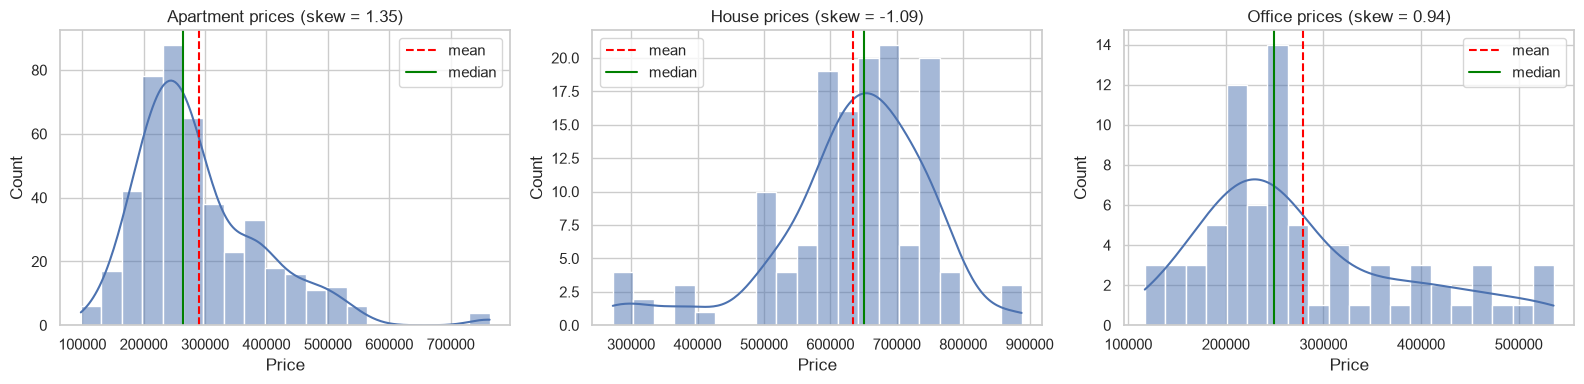

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, (ptype, grp) in zip(axes, fl.groupby("Type of property")):
    sns.histplot(grp["Price"], bins=20, kde=True, ax=ax)
    ax.axvline(grp["Price"].mean(), color="red", ls="--", label="mean")
    ax.axvline(grp["Price"].median(), color="green", ls="-", label="median")
    ax.set_title(f"{ptype} prices (skew = {grp['Price'].skew():.2f})")
    ax.legend()
plt.tight_layout(); plt.show()

### Understanding this chart code
- `plt.subplots(1, 3, ...)` creates three chart areas side by side.
- `fl.groupby(...)` provides one subset of properties at a time.
- `sns.histplot(...)` groups prices into bins (bars); `kde=True` overlays a smoothed density curve.
- `ax.set_title(...)` labels each chart, and `plt.tight_layout()` improves spacing.

**Analyst-to-manager interpretation:** Each panel shows how common different price ranges are for one property type. Look for the main cluster, long tails, gaps, and isolated bars. A few high-price properties can affect the mean substantially, so investigate them before deciding whether they are errors.

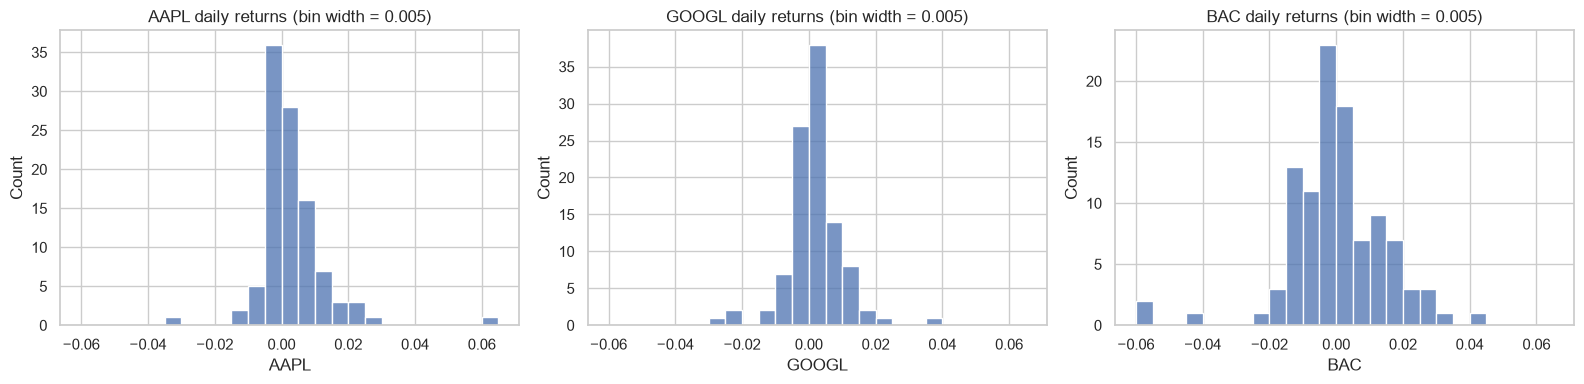

AAPL outliers: [0.061, 0.0204, 0.0207, 0.0204, 0.0272, -0.0336]
GOOGL outliers: [0.0196, -0.0139, -0.0251, -0.0205, 0.0178, 0.0233, 0.0371, -0.0233]
BAC outliers: [-0.0417, 0.0332, -0.0581, 0.0405, -0.0592]


In [7]:
# Stock returns: fixed bin width of 0.005, as in the exam
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, col in zip(axes, ["AAPL", "GOOGL", "BAC"]):
    lo, hi = sr[col].min(), sr[col].max()
    bins = np.arange(np.floor(lo / 0.005) * 0.005, hi + 0.005, 0.005)
    sns.histplot(sr[col], bins=bins, ax=ax)
    ax.set_title(f"{col} daily returns (bin width = 0.005)")
plt.tight_layout(); plt.show()

# Flag outliers with the 1.5 x IQR rule
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
for col in ["AAPL", "GOOGL", "BAC"]:
    print(col, "outliers:", iqr_outliers(sr[col]).round(4).tolist())

### Understanding this chart code
- The loop creates one histogram for each stock's daily returns.
- `lo` and `hi` identify a range for the histogram bins; `np.arange(...)` creates evenly spaced bin boundaries.
- `sns.histplot(...)` counts observations in each return range.
- The shared x-axis makes the three distributions easier to compare visually.

**Analyst-to-manager interpretation:** The charts show how often each stock had small versus large daily movements. Wider distributions indicate more day-to-day variability. Extreme returns should be checked against market events and data quality, not automatically removed.

**Interpretation:** most days cluster tightly around zero, with a few extreme days in the tails. Those are the outliers. Don't delete them automatically: ask whether they are errors or real events (earnings, news).

## 1.5 Covariance, correlation, and coefficient of variation
- **Covariance**: do two variables move together? Sign shows direction, but the size depends on units, so it's hard to compare.
- **Correlation (Pearson, r)**: covariance rescaled to [-1, +1]. Easy to interpret.
- **Coefficient of Variation (COV)** = std / mean: risk *per unit of average return*. **Lower COV = more return for the risk taken.**

**Everyday analogy:** covariance and correlation are like checking whether umbrella sales and raincoat sales rise together. Correlation puts the relationship on a common scale, while covariance remains tied to the units used.

**Common beginner mistakes**
- Saying correlation proves causation. A third factor may influence both variables.
- Treating a correlation near zero as proof that no relationship exists; a nonlinear relationship may still be present.
- Comparing covariance values across variables measured in different units.
- Interpreting coefficient of variation when the mean is near zero or negative.

Covariance matrix


,AAPL,GOOGL,BAC
AAPL,0.0001,0.0000,0.0001
GOOGL,0.0000,0.0001,0.0001
BAC,0.0001,0.0001,0.0002


Correlation matrix


,AAPL,GOOGL,BAC
AAPL,1.0000,0.2694,0.4270
GOOGL,0.2694,1.0000,0.4498
BAC,0.4270,0.4498,1.0000


,mean return,std dev,COV (std/mean)
AAPL,0.0027,0.0097,3.5346
GOOGL,0.0020,0.0083,4.1636
BAC,0.0002,0.0151,96.2041


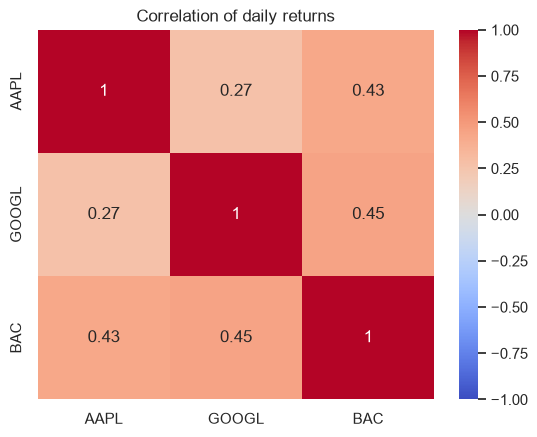

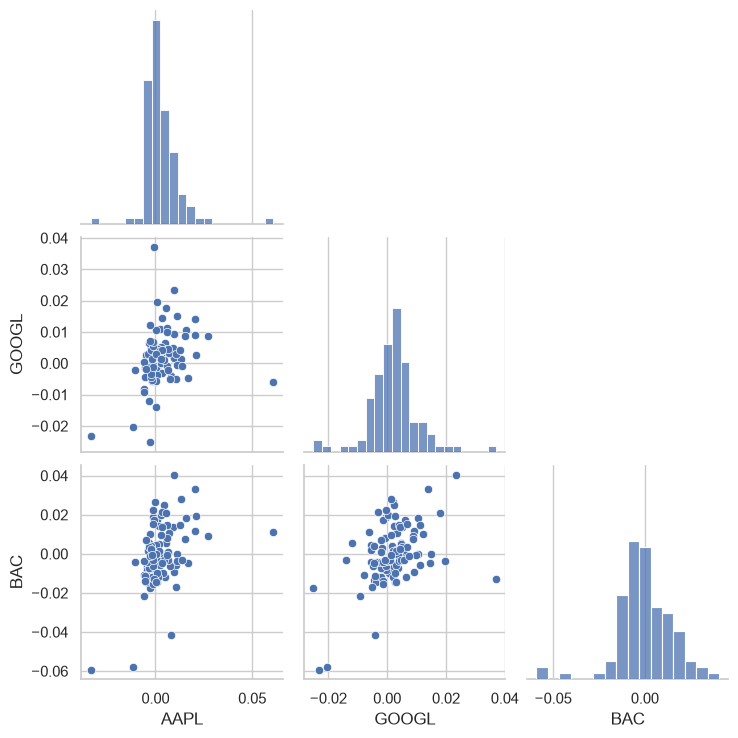

In [8]:
rets = sr[["AAPL", "GOOGL", "BAC"]]
print("Covariance matrix"); display(rets.cov())
print("Correlation matrix"); display(rets.corr())

cov_table = pd.DataFrame({"mean return": rets.mean(), "std dev": rets.std(), "COV (std/mean)": rets.std() / rets.mean()})
display(cov_table)

sns.heatmap(rets.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of daily returns"); plt.show()
sns.pairplot(rets, corner=True); plt.show()

### Understanding this code and its output
- `rets.cov()` calculates pairwise covariance; `rets.corr()` calculates Pearson correlation for every pair of stocks.
- `.mean()` and `.std(ddof=1)` summarize each return series.
- `pd.DataFrame({...})` puts the mean, standard deviation, and coefficient of variation into one comparison table.
- The coefficient of variation is standard deviation divided by mean; it can be misleading when the mean is near zero.

**Analyst-to-manager interpretation:** Correlation describes how consistently two stocks move together, not whether one causes the other to move. Lower correlations can offer diversification benefits. Treat the coefficient of variation cautiously when average returns are close to zero.

**Interpretation**
- All covariances and correlations are **positive** (about 0.27 to 0.45): the stocks tend to move in the same direction, but only moderately. That gives some diversification benefit, but not much.
- **COV:** Apple ≈ 3.5, Google ≈ 4.2, BAC ≈ 96. BAC's average return is nearly zero relative to its swings, so it carries by far the most risk per unit of return in this sample.
- Caution: COV is unstable when the mean is close to zero, as with BAC here.

# Module 2: Normal Distribution and Sampling

## 2.1 Properties of the normal distribution
- Bell-shaped and **symmetric** around the mean.
- **Mean = median = mode**, and **skewness = 0**.
- Fully described by two parameters: mean (μ) and standard deviation (σ).
- **Empirical rule:** about 68% of values lie within ±1σ, 95% within ±2σ, 99.7% within ±3σ.

**Everyday analogy:** a normal distribution resembles the pattern of many small, independent influences adding together—such as measurement variation around a production target. Most results are near the center and very high or low results become progressively less common.

**Common beginner mistakes**
- Assuming real-world data must be normal just because a statistical method is familiar.
- Applying the 68–95–99.7 rule to a strongly skewed distribution.
- Thinking a bell-shaped histogram proves normality; use context and, when needed, additional diagnostics.

n = 80
mean=7161.71  median=7206.75  std=712.80  skew=-0.393


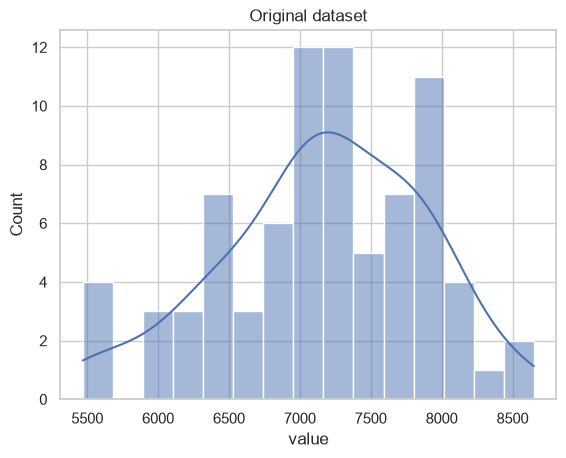

within ±1σ: 65.0%
within ±2σ: 93.8%
within ±3σ: 100.0%


In [9]:
nd = load("Normal Distribution.xlsx", header_text="Original dataset")
x = pd.to_numeric(nd.iloc[:, 0]).dropna().reset_index(drop=True)
x.name = "value"
print("n =", len(x))
print(f"mean={x.mean():.2f}  median={x.median():.2f}  std={x.std():.2f}  skew={x.skew():.3f}")

sns.histplot(x, bins=15, kde=True); plt.title("Original dataset"); plt.show()

# Check the empirical rule
for k in (1, 2, 3):
    share = ((x > x.mean() - k * x.std()) & (x < x.mean() + k * x.std())).mean()
    print(f"within ±{k}σ: {share:.1%}")

### Understanding this code and its output
- `load(...)` reads the normal-distribution example spreadsheet.
- `nd.iloc[:, 0]` selects the first column by position; `pd.to_numeric(...)` converts it to numbers.
- `.dropna()` removes missing values, and `.reset_index(drop=True)` gives the cleaned series a fresh index.
- `.mean()`, `.median()`, `.std(ddof=1)`, and `.skew()` summarize center, spread, and asymmetry.
- The empirical-rule calculations count values within one, two, and three standard deviations of the mean.

**Analyst-to-manager interpretation:** These figures describe whether the observed values are reasonably balanced around their average and how much variation is typical. The 68–95–99.7 rule is a reference for approximately normal data, not a guarantee for every dataset.

**Interpretation:** mean and median are close and skewness is small (about -0.39), so the data is *approximately* normal. The empirical-rule shares should land near 68 / 95 / 99.7%.

## 2.2 Standardization (Z-scores)
$$z = \frac{x - \mu}{\sigma}$$
A Z-score says **how many standard deviations a value sits from the mean**. This puts values from different distributions on the same scale. Standardized data always has mean 0 and standard deviation 1.

**Everyday analogy:** a Z-score is like saying a student's score is not just 85 points, but 1.2 class-standard-deviations above the class average. It gives context relative to the group's usual spread.

**Common beginner mistakes**
- Confusing a Z-score of 2 with a value that is two times the mean. It means two standard deviations above the mean.
- Forgetting the sign: negative is below the mean; positive is above.
- Using population and sample standard deviations inconsistently. In this notebook, sample standardization uses `ddof=1`.
- Assuming a high absolute Z-score automatically means a data error.

In [10]:
z = (x - x.mean()) / x.std(ddof=1)          # same as stats.zscore(x, ddof=1)
print(f"standardized mean = {z.mean():.4f}, std = {z.std(ddof=1):.4f}")
print(f"highest standardized value: {z.max():.4f}  (original value {x[z.idxmax()]:.2f})")
print(f"lowest standardized value:  {z.min():.4f}  (original value {x[z.idxmin()]:.2f})")
print("values beyond |z| > 2:", int((z.abs() > 2).sum()))

# Probability view: how unusual is the top value?
print(f"P(Z > {z.max():.2f}) = {1 - stats.norm.cdf(z.max()):.4f}")

standardized mean = 0.0000, std = 1.0000
highest standardized value: 2.0881  (original value 8650.12)
lowest standardized value:  -2.3742  (original value 5469.40)
values beyond |z| > 2: 5
P(Z > 2.09) = 0.0184


### Understanding this code and its output
- `(x - x.mean())` centers each observation around the sample mean.
- Dividing by `x.std(ddof=1)` expresses each difference in standard-deviation units.
- `ddof=1` requests the sample standard deviation, matching pandas' default for `.std()`.
- `z.mean()` and `z.std(...)` check that the transformed values are centered near zero with a standard deviation near one.
- `.idxmax()` / `.max()` identify the largest standardized observation.

**Analyst-to-manager interpretation:** A Z-score makes it easier to compare an observation with the dataset's usual variation. A score near +2 means the value is about two standard deviations above the average. It flags an unusual observation for review; it does not prove that the value is wrong.

**Interpretation:** the highest value is roughly **2.09 standard deviations above the mean**. That's unusual (only about 1.8% of a normal population lies this high) but not extreme enough to call a clear outlier.

## 2.3 Central Limit Theorem (CLT)
> No matter the shape of the population, the distribution of **sample means** approaches a **normal** distribution as the sample size *n* grows, with mean μ and standard deviation σ/√n.

This is why we can build confidence intervals and run tests on averages even when the raw data isn't perfectly normal. Let's prove it with a deliberately **non-normal** population.

**Everyday analogy:** imagine repeatedly taking random groups of customers and calculating each group's average spending. Individual customers may have a very uneven spending pattern, but the averages across many repeated groups tend to form a more regular, bell-shaped pattern as the group size grows.

**Common beginner mistakes**
- Thinking the CLT says the original raw data becomes normal. It is the distribution of sample means that becomes approximately normal.
- Believing any tiny sample is automatically safe; the sample size needed depends partly on population skewness and outliers.
- Ignoring independence, random sampling, or severe data-collection bias. A large biased sample is still biased.

population: mean=50.17, std=50.26, skew=2.02


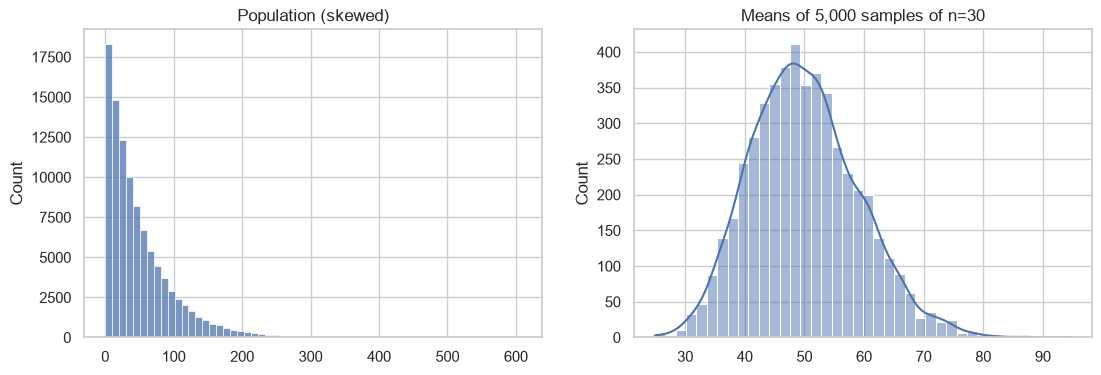

mean of sample means = 50.01   (≈ population mean)
std of sample means  = 9.01   (theory σ/√n = 9.18)
skew of sample means = 0.37   (much closer to 0)


In [11]:
rng = np.random.default_rng(42)
population = rng.exponential(scale=50, size=100_000)       # heavily right-skewed
print(f"population: mean={population.mean():.2f}, std={population.std():.2f}, skew={stats.skew(population):.2f}")

n, n_samples = 30, 5_000
sample_means = np.array([rng.choice(population, size=n).mean() for _ in range(n_samples)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(population, bins=60, ax=ax[0]); ax[0].set_title("Population (skewed)")
sns.histplot(sample_means, bins=40, kde=True, ax=ax[1]); ax[1].set_title(f"Means of {n_samples:,} samples of n={n}")
plt.show()

print(f"mean of sample means = {sample_means.mean():.2f}   (≈ population mean)")
print(f"std of sample means  = {sample_means.std(ddof=1):.2f}   (theory σ/√n = {population.std()/np.sqrt(n):.2f})")
print(f"skew of sample means = {stats.skew(sample_means):.2f}   (much closer to 0)")

### Understanding this simulation
- `np.random.default_rng(42)` creates a random-number generator; the seed `42` makes the example reproducible.
- `rng.exponential(...)` creates a deliberately right-skewed population.
- `rng.choice(...)` repeatedly draws random samples from that population.
- `np.mean(...)` calculates each sample's average; the histogram compares those averages.
- The loop repeats the sampling experiment for different sample sizes.

**Analyst-to-manager interpretation:** Even though individual observations are strongly skewed, averages from repeated samples become more bell-shaped as sample size increases. This helps explain why methods based on sample averages can work well, provided the sample is sufficiently large and observations are appropriately collected.

**Interpretation:** the population is very skewed, yet the sample means form a near-bell shape centered on the true mean. Their spread matches σ/√n. Try changing `n` to 5, then 100, and watch the shape change.

## 2.4 Standard error of the mean
$$SE = \frac{s}{\sqrt{n}}$$
The **standard error** is the standard deviation of the *sample mean*. It tells you how precisely a sample mean estimates the population mean: bigger *n* means smaller SE.

**Everyday analogy:** standard deviation is how much individual delivery times vary; standard error is how much the average delivery time would vary if you repeatedly sampled different groups of deliveries. One describes individual spread, the other precision of an estimate.

**Common beginner mistakes**
- Calling standard deviation and standard error the same thing.
- Using `s` instead of `s / sqrt(n)` when calculating the standard error of a mean.
- Expecting standard error to halve when sample size doubles. It halves when sample size is multiplied by four.
- Forgetting `ddof=1` when estimating sample standard deviation in NumPy.

In [12]:
se = x.std(ddof=1) / np.sqrt(len(x))
print(f"Standard error of the mean = {se:.2f}")
print(f"(same via scipy: {stats.sem(x):.2f})")
for n_ in (20, 80, 320):
    print(f"n = {n_:>3}: SE = {x.std(ddof=1)/np.sqrt(n_):.2f}")

Standard error of the mean = 79.69
(same via scipy: 79.69)
n =  20: SE = 159.39
n =  80: SE = 79.69
n = 320: SE = 39.85


### Understanding this code and its output
- `x.std(ddof=1)` estimates the sample's standard deviation.
- `np.sqrt(len(x))` calculates the square root of the sample size.
- Dividing the standard deviation by that square root estimates the standard error of the mean.
- `stats.sem(x)` is SciPy's helper function for calculating the standard error; it uses the sample standard deviation by default.
- The loop illustrates how the standard error changes at different sample sizes.

**Analyst-to-manager interpretation:** Standard deviation describes variation among individual observations. Standard error describes how much the sample average would typically vary across repeated samples. More observations generally make the average more precise, but precision improves with the square root of sample size—not in direct proportion.

**Interpretation:** quadrupling the sample size only halves the standard error, which is the "square-root law" of precision.

# Module 3: Confidence Intervals

## 3.1 Parameter vs. estimator vs. estimate
| Term | Meaning | Example |
|---|---|---|
| **Parameter** | A fixed (usually unknown) property of the *population* | True mean Mouse X price, μ |
| **Estimator** | The *rule/formula* applied to a sample | The sample-mean formula, x̄ = Σx / n |
| **Estimate** | The *number* you get from your particular sample | x̄ = 108.13 |

A **confidence interval (CI)** gives a range of plausible values for the parameter:
$$\text{CI} = \text{point estimate} \pm \text{margin of error}$$
The sample mean sits exactly at the **midpoint** of the CI. Margin of error **grows** with higher confidence and larger standard deviation, and **shrinks** with larger *n*.

**Everyday analogy:** a population parameter is the true average delivery time for every delivery this year; an estimator is the recipe for calculating an average from a sample; an estimate is the actual number produced by your selected deliveries. A confidence interval adds a reasonable uncertainty range around that estimate.

**Common beginner mistakes**
- Saying there is a 95% probability that the fixed population mean lies in this already-calculated 95% interval. The frequentist interpretation is about the long-run coverage of the method.
- Thinking a wider interval is always worse; it may reflect a smaller sample, greater variability, or a higher confidence level.
- Forgetting that confidence intervals rely on sampling and model assumptions.

In [13]:
mouse = load("GearX.xlsx", sheet="Mouse X", header_text="SalePrice")
mouse["SalePrice"] = pd.to_numeric(mouse["SalePrice"])
kb = load("GearX.xlsx", sheet="Keyboard X", header_text="SalePrice")
kb["SalePrice"] = pd.to_numeric(kb["SalePrice"])
print("Mouse X n =", len(mouse), "| Keyboard X n =", len(kb))
display(mouse.head(3))

Mouse X n = 75 | Keyboard X n = 61


,Date,Country,ProductID,SalePrice
0,2018-01-03 15:59:12,United States,MouseX,120.4000
1,2018-01-26 11:11:12,United States,MouseX,94.8000
2,2018-02-13 11:25:36,United States,MouseX,60.0000


### Understanding this code and its output
- The three `load(...)` calls read the Mouse X, Keyboard X, and comparison worksheets.
- `pd.to_numeric(...)` ensures the sale-price columns are numeric.
- `.dropna()` removes missing observations from the relevant samples.
- `.mean()`, `.std(ddof=1)`, and `len(...)` calculate each sample's mean, sample spread, and size.

**Analyst-to-manager interpretation:** This is the descriptive groundwork for estimating average sale prices. Always report the sample size alongside an average: a mean based on a handful of sales is generally less precise than one based on many sales.

## 3.2 CI with the Z-distribution (population σ known)
Use Z when the **population standard deviation is known** (here σ = \$30 for Mouse X):
$$\bar{x} \pm z_{\alpha/2}\,\frac{\sigma}{\sqrt{n}}$$

**Everyday analogy:** if a factory genuinely knows the long-run standard deviation of bottle fill volume, it can use that known spread to estimate the uncertainty around a sample's average fill. In practice, truly known population standard deviations are uncommon.

**Common beginner mistakes**
- Using a Z interval just because the sample is large. The key distinction here is whether population σ is known; when it is unknown, a t interval is generally appropriate.
- Putting the standard deviation directly into the margin of error instead of dividing by `sqrt(n)`.
- Confusing the confidence level with the critical value.

In [14]:
sigma = 30
xbar, n = mouse["SalePrice"].mean(), len(mouse)
conf = 0.95
z_crit = stats.norm.ppf(1 - (1 - conf) / 2)       # 1.96 for 95%
moe = z_crit * sigma / np.sqrt(n)
print(f"x̄ = {xbar:.2f}, n = {n}, z* = {z_crit:.3f}, margin of error = {moe:.2f}")
print(f"95% Z-CI: ({xbar - moe:.2f}, {xbar + moe:.2f})")

# Shortcut: scipy does the same thing
print("scipy check:", stats.norm.interval(conf, loc=xbar, scale=sigma / np.sqrt(n)))

x̄ = 108.13, n = 75, z* = 1.960, margin of error = 6.79
95% Z-CI: (101.34, 114.92)
scipy check: (np.float64(101.34368559554298), np.float64(114.92271440445703))


### Understanding this code and its output
- `stats.norm.ppf(...)` finds the Z critical value that leaves the requested probability in the tails (about 1.96 for a two-sided 95% interval).
- `sigma / np.sqrt(n)` is the standard error when the population standard deviation is known.
- Multiplying the critical value by the standard error gives the margin of error.
- The lower and upper limits are the sample mean minus/plus that margin.

**Analyst-to-manager interpretation:** The interval gives a range of plausible values for the population's average sale price under the stated sampling assumptions. The 95% confidence level describes the long-run success rate of this interval-building method; it does not mean there is a 95% probability that this one fixed interval contains the fixed population mean.

**Interpretation:** we are 95% confident the true average Mouse X sale price is between the two printed values. Strictly, "95%" means that if we repeated the sampling many times, about 95% of intervals built this way would contain the true mean.

## 3.3 CI with the T-distribution (population σ unknown)
When σ is **unknown** (the usual real-world case), estimate it with the sample standard deviation *s* and use the **t-distribution** with *n - 1* degrees of freedom (fatter tails, so wider intervals for small samples):
$$\bar{x} \pm t_{\alpha/2,\,n-1}\,\frac{s}{\sqrt{n}}$$

**How `scipy.stats.t.interval()` works:** `stats.t.interval(confidence, df, loc=mean, scale=standard_error)`. Note that the `scale` is the **standard error** (s/√n), not s itself. This is the most common mistake.

**Everyday analogy:** when you do not know the true variation in all customer transactions, you estimate it from the transactions you sampled. The t distribution allows for the extra uncertainty caused by estimating that spread.

**Common beginner mistakes**
- Passing the sample standard deviation as `scale` to `stats.t.interval()`. The `scale` argument must be the standard error, `s / sqrt(n)`.
- Using degrees of freedom equal to `n` instead of `n - 1` for a one-sample t interval.
- Assuming t and Z intervals are always identical; they are more different with small samples.

In [15]:
k = kb["SalePrice"]
n_k, xbar_k, s_k = len(k), k.mean(), k.std(ddof=1)
se_k = s_k / np.sqrt(n_k)

# Manual
t_crit = stats.t.ppf(0.975, df=n_k - 1)
print(f"Manual: t* = {t_crit:.3f}, CI = ({xbar_k - t_crit*se_k:.2f}, {xbar_k + t_crit*se_k:.2f})")

# scipy
lo, hi = stats.t.interval(0.95, df=n_k - 1, loc=xbar_k, scale=se_k)
print(f"scipy:  CI = ({lo:.2f}, {hi:.2f})")

# Compare with the Z critical value
print(f"For reference z* = 1.960 vs t* = {t_crit:.3f} (t is slightly wider)")

Manual: t* = 2.000, CI = (94.39, 108.47)
scipy:  CI = (94.39, 108.47)
For reference z* = 1.960 vs t* = 2.000 (t is slightly wider)


### Understanding this code and its output
- `k.std(ddof=1)` estimates the unknown population spread using the sample.
- `s_k / np.sqrt(n_k)` calculates the standard error of the sample mean.
- `stats.t.ppf(...)` obtains the t critical value using `df=n_k - 1` degrees of freedom.
- The manual calculation constructs the interval from the critical value and standard error.
- `stats.t.interval(...)` performs the same interval calculation when given the confidence level, degrees of freedom, sample mean (`loc`), and standard error (`scale`).

**Analyst-to-manager interpretation:** This interval estimates the average Keyboard X sale price while allowing for uncertainty because the true population standard deviation is unknown. The t distribution accounts for the extra uncertainty involved in estimating spread from the sample.

**Interpretation:** the interval is centered on the Keyboard X sample mean (~\$101.43). With n = 61 the t critical value is close to 1.96, so t and z intervals are very similar. They differ a lot only for small samples.

## 3.4 CI for the difference between two independent means
The `US10 vs US12` sheet holds Keyboard X sale prices for two groups (e.g. before vs after a price change). The groups have **different sizes and are independent**, so we build a CI for **μ₂ - μ₁**.

We show both versions:
- **Pooled variance** (assumes equal variances)
- **Welch** (doesn't assume equal variances; safer default)

**Everyday analogy:** compare average order values from two separate stores. The groups are independent if a customer's order in one store is not naturally paired with an order from the other store. A difference interval estimates how far apart the stores' true average order values may be.

**Common beginner mistakes**
- Using an independent-groups method when observations are actually matched (or vice versa).
- Reversing the subtraction order. The sign changes if you calculate group 1 minus group 2 instead of group 2 minus group 1.
- Assuming equal variances without checking. Welch's method is a useful default when that assumption is not justified.
- Treating an interval that crosses zero as proof the groups are identical.

In [16]:
ab = load("GearX.xlsx", sheet="US10 vs US12", header_text="US10")
g10 = pd.to_numeric(ab.iloc[:, 0]).dropna()
g12 = pd.to_numeric(ab.iloc[:, 1]).dropna()
n1, n2 = len(g10), len(g12)
diff = g12.mean() - g10.mean()
v1, v2 = g10.var(ddof=1), g12.var(ddof=1)
print(f"US10: n={n1}, mean={g10.mean():.2f} | US12: n={n2}, mean={g12.mean():.2f} | difference (US12-US10) = {diff:.2f}")

# Pooled
sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
se_p = np.sqrt(sp2 * (1 / n1 + 1 / n2))
tc = stats.t.ppf(0.975, n1 + n2 - 2)
print(f"Pooled 95% CI for difference: ({diff - tc*se_p:.2f}, {diff + tc*se_p:.2f})")

# Welch
se_w = np.sqrt(v1 / n1 + v2 / n2)
dfw = se_w**4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
tcw = stats.t.ppf(0.975, dfw)
print(f"Welch  95% CI for difference: ({diff - tcw*se_w:.2f}, {diff + tcw*se_w:.2f})   [df = {dfw:.1f}]")

US10: n=6, mean=77.74 | US12: n=12, mean=113.63 | difference (US12-US10) = 35.89
Pooled 95% CI for difference: (3.54, 68.23)
Welch  95% CI for difference: (4.79, 66.98)   [df = 12.1]


### Understanding this code and its output
- The two columns are cleaned into separate numeric samples, `g10` and `g12`.
- `len(...)`, `.mean()`, and `.var(ddof=1)` summarize each group.
- The pooled method combines the two sample variances under an equal-variance assumption.
- Welch's method allows the groups to have different variances and uses an adjusted degrees-of-freedom calculation.
- The interval is for the difference in means, in the order stated in the notebook: group 12 minus group 10.

**Analyst-to-manager interpretation:** The interval estimates how much the average sale price differs between the two independent groups. If the entire interval is above zero, the data supports a higher average for group 12; if it crosses zero, the direction is less certain. The width communicates how precise that estimate is.

**Interpretation:** the whole interval is **above zero**, so zero (no price difference) is *not* a plausible value, which is evidence that the average sale price is higher for US12 than for US10. A CI that contains 0 would mean the difference isn't statistically distinguishable from none. The estimate is imprecise because the US10 group has only 6 observations.

# Module 4: Hypothesis Testing

## 4.1 The four steps
1. **Formulate** the hypotheses: null **H₀** (status quo / "no effect") and alternative **H₁** (what you're looking for evidence of).
2. **Find the right test:** one sample or two? σ known (Z) or unknown (T)? paired or independent?
3. **Execute:** compute the test statistic and p-value (or compare with the critical value).
4. **Decide:** if p-value < α (usually 0.05) **reject H₀**; otherwise **fail to reject** it. Then translate it into a business statement.

## 4.2 Errors, power, and p-values
| | H₀ true | H₀ false |
|---|---|---|
| **Reject H₀** | **Type I error** (false positive), probability α | Correct (probability = **power**, 1 - β) |
| **Fail to reject** | Correct | **Type II error** (false negative), probability β |

- **p-value** = probability of seeing data *at least this extreme* **assuming H₀ is true**.
- It is **not** the probability that H₀ is true, and **not** the probability of a Type II error.
- "Fail to reject" is *not* the same as "H₀ is proven".

**Everyday analogy:** a manager claims a new checkout process changes average waiting time. A hypothesis test is a structured way to ask whether the observed sample provides enough evidence to challenge the current assumption, while recognizing that random variation can mislead us.

**Common beginner mistakes**
- Treating the p-value as the probability that the null hypothesis is true. It is calculated assuming the null hypothesis is true.
- Saying a small p-value tells you the effect is large or important. Statistical evidence and business impact are different.
- Saying “accept the null” after a non-significant result. Use “fail to reject”; the data may simply be inconclusive.
- Choosing a one-sided test after seeing the data. The direction should be justified before examining the result.
- Ignoring assumptions such as random sampling, independence, and appropriate measurement.

In [17]:
def load_col(sheet, header_text):
    d = load("House Prices USA.xlsx", sheet=sheet, header_text=header_text)
    return d

pa = pd.to_numeric(load_col("PA House Prices", "House Price").iloc[:, 0])
tx = pd.to_numeric(load_col("TX House Prices", "House Price").iloc[:, 0])
ga = load_col("GA Housing Regulation ", "House Price (Before)").iloc[:, :2].apply(pd.to_numeric)
ga.columns = ["Before", "After"]
print("PA n =", len(pa), "| TX n =", len(tx), "| GA pairs =", len(ga))

PA n = 30 | TX n = 15 | GA pairs = 9


### Understanding this code and its output
- `load_col(...)` is a small helper function that avoids repeating the spreadsheet-loading steps.
- Each sheet is loaded, and `pd.to_numeric(...)` prepares its price column for calculations.
- The code creates the Pennsylvania (`pa`), Texas (`tx`), and Georgia (`ga`) datasets used in the tests below.
- `dropna()` excludes missing values from the analysis.

**Analyst-to-manager interpretation:** This cell prepares three state-level datasets for separate questions. Before interpreting any test, check that each sheet represents the intended population, that prices use consistent units, and that missing values have been handled appropriately.

## 4.3 One-sample T-test: PA average house price vs \$350,000
- **H₀:** μ = 350,000  **H₁:** μ ≠ 350,000 (two-tailed)
- σ unknown → **T-test**, df = n - 1, α = 0.05

**Everyday analogy:** a property analyst wants to check whether the average price in a region differs from a published benchmark. The one-sample t-test compares the sample average with that benchmark while accounting for uncertainty in the estimated standard deviation.

**Common beginner mistakes**
- Using a one-sample test when the observations actually form two groups or matched pairs.
- Misreading a tiny p-value as the probability that the null hypothesis is true.
- Reporting only “significant” without reporting the sample mean and the size of the difference.

In [18]:
alpha = 0.05
res = stats.ttest_1samp(pa, popmean=350_000)          # two-sided by default
print(f"PA: n={len(pa)}, mean={pa.mean():,.0f}, std={pa.std():,.0f}")
print(f"t = {res.statistic:.3f}, p-value = {res.pvalue:.2e}")
t_crit = stats.t.ppf(1 - alpha / 2, df=len(pa) - 1)
print(f"critical values: ±{t_crit:.3f}")
print("Decision:", "Reject H0" if res.pvalue < alpha else "Fail to reject H0")

PA: n=30, mean=179,200, std=46,927
t = -19.936, p-value = 1.79e-18
critical values: ±2.045
Decision: Reject H0


### Understanding this test and its output
- `stats.ttest_1samp(pa, popmean=350_000)` compares the sample mean with the hypothesized value of $350,000.
- Under the hood, SciPy calculates the difference between the sample mean and hypothesized mean, divides it by the estimated standard error, and evaluates the resulting t statistic using a t distribution with `n - 1` degrees of freedom.
- The default alternative is two-sided: it looks for a difference in either direction.
- `res.statistic` is the t statistic and `res.pvalue` is the p-value.

**Analyst-to-manager interpretation:** The test assesses whether the Pennsylvania sample provides evidence that its population average differs from $350,000. A very small p-value is evidence against the benchmark under the test assumptions; it does not measure the size or business importance of the difference.

**Decision:** the sample mean (~\$179,200) is far below \$350,000 (t ≈ -19.9, p ≈ 0). **Reject H₀:** PA house prices are significantly different from \$350,000 (in fact much lower).

## 4.4 One-sample Z-test: TX house prices ≤ \$200,000
- **H₀:** μ ≤ 200,000 (the claim)  **H₁:** μ > 200,000 (right-tailed)
- Population σ is assumed **known** → **Z-test**: 
$$z = \frac{\bar{x} - \mu_0}{\sigma/\sqrt{n}}$$

> ⚠️ **Set `POP_SIGMA` to the value given in your exam.** The data file doesn't contain it, so I use \$40,000 as a placeholder (close to the sample standard deviation of ~\$42,500).

**Everyday analogy:** a regulator asks whether average prices exceed a threshold. This is like a smoke alarm designed to detect values above a specified limit: the question is directional, so the alternative hypothesis is “greater than.”

**Common beginner mistakes**
- Using a population standard deviation that is not actually known. This example uses a placeholder; conclusions can change if it changes.
- Using a two-sided critical value for a one-sided test, or using the wrong tail.
- Forgetting that “fail to reject” does not prove the threshold claim is true.

In [19]:
POP_SIGMA = 40_000        # <-- replace with the population std from the exam question
mu0 = 200_000
n_tx, xbar_tx = len(tx), tx.mean()

z_stat = (xbar_tx - mu0) / (POP_SIGMA / np.sqrt(n_tx))
p_right = 1 - stats.norm.cdf(z_stat)                 # right-tailed
z_crit = stats.norm.ppf(1 - alpha)                   # 1.645
print(f"TX: n={n_tx}, mean={xbar_tx:,.0f}")
print(f"z = {z_stat:.3f}, critical z (right-tail, α=0.05) = {z_crit:.3f}, p-value = {p_right:.4f}")
print("Decision:", "Reject H0" if z_stat > z_crit else "Fail to reject H0")

TX: n=15, mean=190,667
z = -0.904, critical z (right-tail, α=0.05) = 1.645, p-value = 0.8169
Decision: Fail to reject H0


### Understanding this Z-test and its output
- The code calculates the standard error using the supplied population standard deviation (`POP_SIGMA`) and sample size.
- `z_stat` measures how many standard errors the sample mean is above or below the benchmark.
- `stats.norm.ppf(1 - alpha)` finds the right-tail critical value for a one-sided test.
- `1 - stats.norm.cdf(z_stat)` calculates the right-tail probability beyond the observed Z statistic.

**Analyst-to-manager interpretation:** This is a one-sided check of whether the Texas population average exceeds $200,000. The conclusion depends on the assumed population standard deviation. Because the notebook uses a placeholder value, replace it with the value specified by the exercise or a defensible population estimate before reporting the result.

**Decision:** z is well below the critical value 1.645 (the sample mean, ~\$190,700, is even *below* \$200,000), so we **fail to reject H₀**: there is no evidence that TX prices exceed \$200,000, which is consistent with the claim.

## 4.5 Paired T-test: GA prices before vs after the regulation
The same houses are measured twice, so the data is **paired**. We test the *differences*:
- **H₀:** μ_diff = 0 (no effect)  **H₁:** μ_diff ≠ 0

**Everyday analogy:** measure the same delivery routes before and after a scheduling change. Each route is its own comparison partner, so the analysis focuses on the change within each route rather than treating the two sets as unrelated.

**Common beginner mistakes**
- Using an independent-samples test for repeated measurements on the same subject.
- Subtracting in the opposite direction and then describing the sign incorrectly.
- Ignoring missing or mismatched pairs. Each before measurement must correspond to the correct after measurement.
- Concluding “no effect” just because the p-value is above 0.05.

mean before = 165,556, mean after = 195,333, mean diff = 29,778
t = -1.300, df = 8, p-value = 0.2297
critical values (two-tailed, α=0.05): ±2.306
Decision: Fail to reject H0


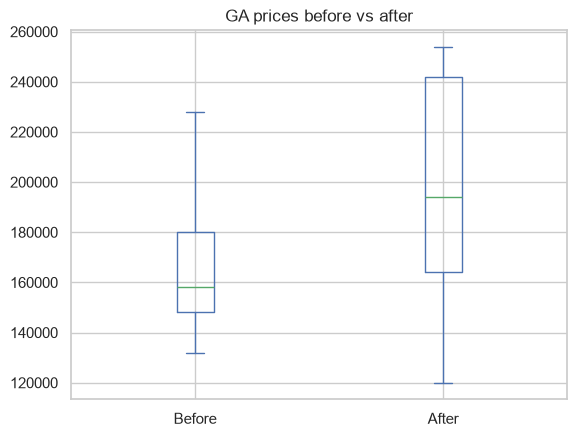

In [20]:
res_p = stats.ttest_rel(ga["Before"], ga["After"])
d = ga["After"] - ga["Before"]
print(f"mean before = {ga['Before'].mean():,.0f}, mean after = {ga['After'].mean():,.0f}, mean diff = {d.mean():,.0f}")
print(f"t = {res_p.statistic:.3f}, df = {len(ga)-1}, p-value = {res_p.pvalue:.4f}")
print(f"critical values (two-tailed, α=0.05): ±{stats.t.ppf(0.975, len(ga)-1):.3f}")
print("Decision:", "Reject H0" if res_p.pvalue < alpha else "Fail to reject H0")

ga.plot(kind="box"); plt.title("GA prices before vs after"); plt.show()

### Understanding this paired test and its output
- `stats.ttest_rel(before, after)` performs a paired t-test: it first considers within-house differences, then tests whether their average difference is zero.
- `ga["After"] - ga["Before"]` creates one difference per house.
- The mean difference describes the average direction and size of the change; the t statistic and p-value quantify evidence against a zero average difference.
- Pairing matters because each before value is naturally matched with the same house's after value.

**Analyst-to-manager interpretation:** The result asks whether the average within-house price change is distinguishable from zero. Report both the estimated change and its uncertainty. A non-significant result means the evidence is insufficient to establish a change; it does not prove that no change occurred.

**Decision:** t ≈ -1.30 (p ≈ 0.23) lies inside ±2.306, so we **fail to reject H₀**. Prices rose by ~\$30,000 on average, but with only 9 houses and a lot of variability, that gap isn't statistically distinguishable from chance. It is **not** proof the regulation had no effect; the test may simply lack power. A larger sample would help.

# Summary cheat sheet
| Question | Tool | Python |
|---|---|---|
| Typical value / spread | mean, median, std | `.mean() .median() .std()` |
| Shape | skewness | `.skew()` |
| Do two variables move together? | correlation | `.corr()` |
| Risk per unit of return | COV | `std / mean` |
| Compare across scales | Z-score | `(x - mean) / std` |
| CI, σ known | Z | `stats.norm.interval` |
| CI, σ unknown | T | `stats.t.interval(conf, df, loc, scale=SE)` |
| One mean vs a number | 1-sample T | `stats.ttest_1samp` |
| Same units, before/after | paired T | `stats.ttest_rel` |
| Two independent groups | 2-sample T | `stats.ttest_ind(equal_var=False)` |

**Decision rule:** p < α → reject H₀. And remember: statistical significance is not the same as practical importance.

## Final beginner checklist
- Identify the question and the population you want to understand.
- Inspect column types, missing values, sample size, and unusual observations.
- Describe center, spread, and shape before selecting a statistical test.
- Distinguish standard deviation (spread of observations) from standard error (precision of an estimate).
- For confidence intervals, state the parameter, confidence level, and interval in business units.
- For hypothesis tests, state H₀, H₁, test direction, test statistic, p-value, decision, and practical meaning.
- Explain results in plain language and mention limitations. Never let a p-value replace business judgment.

**Remember:** statistics does not remove uncertainty. It makes uncertainty visible so decisions can be better informed.